In [1]:
from legendmeta import LegendMetadata
from dbetto import Props, TextDB
from datetime import datetime
import json
import yaml
import collections


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
#We will start by importing and constructing the (LegendMetadata)
#[https://pylegendmeta.readthedocs.io/en/stable/api/legendmeta.html#legendmeta.core.LegendMetadata] object. If no argument is provided, the most recent version of legend-metadata will be fetched from github. 
#Instead, we will grab the version that was used for the nu24 analysis

In [3]:
# Pretty print nested dict/list structures
def pprint(val, nlines=None):
    # Don't think too hard about this...If it bothers you, go to the Juleana tutorial instead
    if nlines is not None:
        print('\n'.join(yaml.safe_dump(json.loads(json.dumps(val, sort_keys=False)), sort_keys=False).split('\n')[:nlines]))
        print('...')
    else:
        print(yaml.safe_dump(json.loads(json.dumps(val, sort_keys=False)), sort_keys=False))

In [4]:
l200_data_dir = "/dvs_ro/cfs/cdirs/m2676/data/lngs/l200/public/prodenv/prod-blind/ref/v2.1.5"
config = Props.read_from(f"{l200_data_dir}/config.json", subst_pathvar=True)["setups"]["l200"]["paths"]
meta = LegendMetadata(config["metadata"])

In [5]:
# clona la versione più recente da github
meta = LegendMetadata()

Cloning git@github.com:legend-exp/legend-metadata in /tmp/legend-metadata-ritaferi...
Checking out the latest stable tag (v1.5.5)...


In [6]:
config;



In [7]:
#pars_pht = TextDB(f"{config['par_pht']}");



In [8]:
meta.keys()

dict_keys(['datasets', 'simprod', 'jldataprod', 'hardware', 'dataprod'])

In [9]:
from pathlib import Path
from itertools import combinations
import pandas as pd

base = Path(
    "/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref"
)
from pathlib import Path

base = Path(
    "/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref"
)
versions = ["v1.0.0", "v1.1.0", "v1.2.1", "v1.2.2"]

# Detector HADES per versione
hades_by_version = {}

for version in versions:
    hit_dir = base / version / "generated/tier/hit"

    if hit_dir.is_dir():
        hades_by_version[version] = {
            p.name for p in hit_dir.iterdir() if p.is_dir()
        }

# Unione dei detector di tutte le versioni HADES
hades_detectors = set().union(*hades_by_version.values())

# Detector presenti nei metadati LEGEND
legend_detectors = set(meta.channelmap().keys())

# Detector comuni
common_detectors = sorted(hades_detectors & legend_detectors)

print(f"Detector HADES: {len(hades_detectors)}")
print(f"Detector nei metadati LEGEND: {len(legend_detectors)}")
print(f"Detector comuni: {len(common_detectors)}")
print(*common_detectors, sep="\n")

Detector HADES: 26
Detector nei metadati LEGEND: 199
Detector comuni: 24
V03421A
V03422A
V04199A
V04545A
V06643A
V06659A
V07298B
V07302A
V07302B
V07647B
V08682A
V08682B
V09372A
V10437B
V10447B
V10784A
V11924A
V11925A
V11947B
V13044A
V13049A
V14618A
V14654A
V14673A


In [10]:


# Unione dei detector di tutte le versioni HADES
hades_detectors = set().union(*hades_by_version.values())

# Detector presenti nei metadati LEGEND
legend_detectors = set(meta.channelmap().keys())

# Detector comuni
common_detectors = sorted(hades_detectors & legend_detectors)

print(f"Detector HADES: {len(hades_detectors)}")


print(f"Detector nei metadati LEGEND: {len(legend_detectors)}")
print(f"Detector comuni: {len(common_detectors)}")
print(*common_detectors, sep="\n")

Detector HADES: 26
Detector nei metadati LEGEND: 199
Detector comuni: 24
V03421A
V03422A
V04199A
V04545A
V06643A
V06659A
V07298B
V07302A
V07302B
V07647B
V08682A
V08682B
V09372A
V10437B
V10447B
V10784A
V11924A
V11925A
V11947B
V13044A
V13049A
V14618A
V14654A
V14673A


In [11]:
 #legend_detectors = set(meta.channelmap().keys())

for version, hades_detectors in hades_by_version.items():
    common = sorted(hades_detectors & legend_detectors)

    print(f"\n{version}: {len(common)}")
    print(*common, sep="\n")


v1.1.0: 8
V03421A
V03422A
V04199A
V04545A
V08682A
V08682B
V09372A
V14673A

v1.2.1: 19
V03421A
V03422A
V06643A
V06659A
V07298B
V07302A
V07302B
V07647B
V10437B
V10447B
V10784A
V11924A
V11925A
V11947B
V13044A
V13049A
V14618A
V14654A
V14673A


# risoluzione

In [48]:
import glob
import yaml

detector = "V14618A"

pattern = (
    "/global/cfs/cdirs/m2676/data/teststands/hades/"
    "prodenv/ref/v1.2.1/generated/par/hit/"
    f"{detector}/c1/am_HS1_lat_dlt/*.yaml"
)

files_par = sorted(glob.glob(pattern))

if not files_par:
    raise FileNotFoundError(f"Nessun file trovato: {pattern}")

print(f"File trovati: {len(files_par)}")

# Carica tutti i YAML: una voce per ogni file.
parameters_by_file = {}

for filename in files_par:
    with open(filename, encoding="utf-8") as stream:
        parameters_by_file[filename] = yaml.safe_load(stream)

    print(filename)



File trovati: 1
/global/cfs/cdirs/m2676/data/teststands/hades/prodenv/ref/v1.2.1/generated/par/hit/V14618A/c1/am_HS1_lat_dlt/char_data-V14618A-am_HS1_lat_dlt-r001-20250604T105822Z-par_hit.yaml


In [49]:
# Dizionario del primo file.

par = parameters_by_file[files_par[0]]
print(par.keys())

dict_keys(['pars', 'results'])


In [55]:
par['results']['ecal']['cuspEmax_ctc_cal']["eres_linear"]

{'function': 'FWHMLinear',
 'module': 'pygama.pargen.energy_cal',
 'expression': '(a+b*x)**(0.5)',
 'parameters': {'a': 0.5399831562577209, 'b': 0.0011019267803187864},
 'uncertainties': {'a': 0.06955380271392347, 'b': 0.0011686814093988661},
 'cov': [[0.0048449521017629995, -8.120960646943744e-05],
  [-8.120960646943744e-05, 1.3666608833650732e-06]],
 'csqr': [2.2965096069109294e-08, -1],
 'p_val': nan}

In [63]:
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(10,3000,3000)
a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["a"]

b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["b"]

c = par['results']['ecal']['cuspEmax_ctc_cal']["eres_quadratic"]["parameters"]["c"]


fwhm_q = (a+b*x+c*x**2)**(0.5)

In [64]:
a = par['results']['ecal']['cuspEmax_ctc_cal']["eres_linear"]["parameters"]["a"]

b = par['results']['ecal']['cuspEmax_ctc_cal']["eres_linear"]["parameters"]["b"]


fwhm_l = (a+b*x)**(0.5)

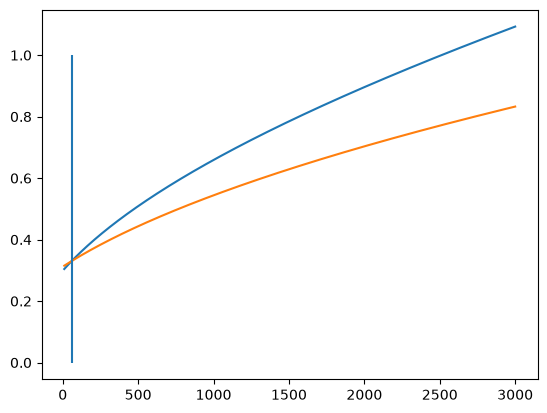

In [67]:
plt.plot(x, fwhm_q / 2.355)
plt.plot(x, fwhm_l / 2.355)
plt.vlines(60, 0, 1 )